In [12]:
# ===== X-Retina bootstrap: paste as the FIRST cell of every notebook =====
# Colab Secrets needed: GITHUB_TOKEN (or GITHUB-TOKEN). Optional: GIT_NAME, GIT_EMAIL, KAGGLE_USERNAME, KAGGLE_KEY
GITHUB_USER = "aimenkhan1"
REPO_NAME   = "X-Retina---Final-Year-Project-"
BRANCH      = "main"

import os, sys, json, subprocess
from google.colab import drive, userdata

def _secret(*names, default=None):
    for n in names:
        try:
            v = userdata.get(n)
            if v:
                return v
        except Exception:
            pass
    return default

GIT_NAME  = _secret("GIT_NAME",  default="X-Retina Team")
GIT_EMAIL = _secret("GIT_EMAIL", default="noreply@users.noreply.github.com")

# 1) Drive + shared folder
drive.mount("/content/drive")
DRIVE_ROOT = "/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared"
assert os.path.isdir(DRIVE_ROOT), (
    f"Shared folder not found at {DRIVE_ROOT}. Add a shortcut named 'XRetina_Shared' to My Drive.")
for _sub in ("processed", "splits", "checkpoints", "outputs"):
    os.makedirs(f"{DRIVE_ROOT}/{_sub}", exist_ok=True)
os.environ["XRETINA_DRIVE_ROOT"] = DRIVE_ROOT
os.makedirs("/content/data/raw", exist_ok=True)
os.environ["XRETINA_RAW_DIR"] = "/content/data/raw"

# 2) Clone or update the repo (token is hidden from error messages)
_token = _secret("GITHUB_TOKEN", "GITHUB-TOKEN")
assert _token, "Add GITHUB_TOKEN (or GITHUB-TOKEN) in Colab Secrets and switch on Notebook access."
REPO_DIR = f"/content/{REPO_NAME}"
_url = f"https://{_token}@github.com/{GITHUB_USER}/{REPO_NAME}.git"

def _run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"{' '.join(cmd[:4])} failed:\n{r.stderr.replace(_token, '***')}")
    return r.stdout.strip()

if not os.path.isdir(REPO_DIR):
    _run(["git", "clone", _url, REPO_DIR])
_run(["git", "-C", REPO_DIR, "remote", "set-url", "origin", _url])
_run(["git", "-C", REPO_DIR, "fetch", "origin"])
try:
    _run(["git", "-C", REPO_DIR, "checkout", BRANCH])
except RuntimeError:
    _run(["git", "-C", REPO_DIR, "checkout", "-b", BRANCH])  # first time on a new branch
try:
    _run(["git", "-C", REPO_DIR, "pull", "origin", BRANCH])
except RuntimeError as e:
    print("Pull skipped (new local branch or local changes):", str(e).splitlines()[-1])
_run(["git", "-C", REPO_DIR, "config", "user.name", GIT_NAME])
_run(["git", "-C", REPO_DIR, "config", "user.email", GIT_EMAIL])

# 3) Requirements
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{REPO_DIR}/requirements.txt"], check=True)

# 4) Kaggle credentials (only needed to download APTOS)
try:
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    _kp = os.path.expanduser("~/.kaggle/kaggle.json")
    with open(_kp, "w") as f:
        json.dump({"username": userdata.get("KAGGLE_USERNAME"), "key": userdata.get("KAGGLE_KEY")}, f)
    os.chmod(_kp, 0o600)
except Exception as e:
    print("Kaggle secrets not set (only needed to download APTOS):", e)

# 5) Make `import src...` work
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

def git_push(message):
    """Commit and push your work directly to the current branch."""
    _run(["git", "-C", REPO_DIR, "add", "-A"])
    print(_run(["git", "-C", REPO_DIR, "commit", "-m", message]))
    print(_run(["git", "-C", REPO_DIR, "push", "-u", "origin", BRANCH]))

from src.config import get_paths
from src.utils import seed_everything, get_device
PATHS = get_paths()
print("Repo:", REPO_DIR, "| Branch:", BRANCH, "| Device:", get_device())
print({k: str(v) for k, v in PATHS.items()})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kaggle secrets not set (only needed to download APTOS): Secret KAGGLE_USERNAME does not exist.
Repo: /content/X-Retina---Final-Year-Project- | Branch: main | Device: cuda
{'drive_root': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared', 'raw': '/content/data/raw', 'processed': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/processed', 'splits': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/splits', 'checkpoints': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/checkpoints', 'outputs': '/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/outputs'}


#1.Settings
Run 1 is TRAIN_ON = "aptos". Run 2 is "both". EPOCHS = None uses the number in configs/baseline.yaml.

In [13]:
TRAIN_ON   = "both"       # APTOS + EyePACS
EPOCHS     = 8            # yaml default is higher than 8 (30)
IMG_SIZE   = 380
BATCH_SIZE = 16
RUN_NAME   = f"baseline_b4_ce_{TRAIN_ON}"

#2. Setup
imports, GPU check and folders. It prints the model and training settings from the yaml file, so you can see the epochs, learning rate and patience.

In [14]:
import time, json, shutil
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, timm
from src.config import load_yaml
from src.data.datasets import extract_shards, load_manifest, build_dataloaders
from src.evaluation.metrics import plot_confusion_matrix, CLASS_NAMES
from src.training.trainer import Trainer, save_metrics

assert torch.cuda.is_available(), "Switch the runtime to T4 GPU, then run the bootstrap cell again."
CFG = load_yaml("baseline.yaml")
seed_everything(CFG["seed"])
PROC, OUT, CKPT = Path(PATHS["processed"]), Path(PATHS["outputs"]), Path(PATHS["checkpoints"])
RUN_DIR = CKPT / RUN_NAME                       # best.pt, last.pt, history.csv (resume lives here)
OUT_RUN = OUT / "baseline" / RUN_NAME           # pictures and test metrics
OUT_RUN.mkdir(parents=True, exist_ok=True)

train_cfg = dict(CFG["train"])
if EPOCHS:
    train_cfg["epochs"] = EPOCHS
print("model:", CFG["model"])
print("train:", train_cfg)
print("checkpoints:", RUN_DIR)

model: {'backbone': 'efficientnet_b4', 'pretrained': True, 'num_classes': 5}
train: {'img_size': 380, 'batch_size': 16, 'mixed_precision': True, 'epochs': 8, 'lr': 0.0001, 'weight_decay': 0.0001, 'scheduler': 'cosine', 'early_stopping_patience': 7, 'monitor': 'qwk', 'grad_clip': 1.0, 'num_workers': 2, 'weighted_sampler': False, 'loss': 'cross_entropy'}
checkpoints: /content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/checkpoints/baseline_b4_ce_both


#3.Load the data
unzips Aiman’s shards to local disk (about a minute), loads manifest.csv, and checks again that no patient is in two splits. Note the always-predict-No-DR number. The model has to beat it.

In [15]:
t0 = time.time()
extract_shards(PROC)
man = load_manifest(PROC) if TRAIN_ON == "both" else load_manifest(PROC, datasets=TRAIN_ON)
print(f"{len(man)} images loaded in {time.time() - t0:.0f} s")

leak = man.groupby(["dataset", "patient_id"])["split"].nunique()
assert (leak == 1).all(), "a patient appears in two splits"
print("Leakage check passed.")
display(pd.crosstab([man["dataset"], man["split"]], man["label"], margins=True))
te = man[man["split"] == "test"]
print(f"Test images: {len(te)} | always-predict-No-DR accuracy: {(te['label'] == 0).mean():.3f}")

All 20 shards ready in /content/data/processed
38788 images loaded in 0 s
Leakage check passed.


label              0     1     2     3     4    All
dataset split                                      
aptos   test     271    56   150    29    44    550
        train   1263   259   699   135   207   2563
        val      271    55   150    29    44    549
eyepacs test    3875   368   790   129   108   5270
        train  18070  1708  3704   611   495  24588
        val     3865   367   798   133   105   5268
All            27615  2813  6291  1066  1003  38788

Test images: 5820 | always-predict-No-DR accuracy: 0.712


#4.Dataloaders
reads the frozen split column (never re-splits), uses train-only augmentation, and builds batches of 16 at 380 px.

In [16]:
loaders = build_dataloaders(man, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
                            num_workers=CFG["train"]["num_workers"], seed=CFG["seed"])
x, y = next(iter(loaders["train"]))
print("train batches per epoch:", len(loaders["train"]))
print("one batch:", tuple(x.shape), x.dtype, "| labels:", y.tolist())

train batches per epoch: 1696
one batch: (16, 3, 380, 380) torch.float32 | labels: [0, 0, 0, 4, 0, 0, 0, 0, 0, 0, 0, 1, 0, 2, 3, 0]


#5.Train (resumes by itself)
this is the long cell. The trainer uses AdamW and a cosine schedule, mixed precision, and early stopping on validation QWK. It saves best.pt and last.pt to Drive after every epoch and writes validation QWK to history.csv. If Colab disconnects, reconnect, press Run all, and it prints “Resumed from ...” and continues. Don’t delete the run folder.

In [17]:
def make_model():
    return timm.create_model(CFG["model"]["backbone"], pretrained=CFG["model"]["pretrained"],
                             num_classes=CFG["model"]["num_classes"])

trainer = Trainer(make_model(), loaders, train_cfg, run_dir=RUN_DIR)
print("device:", trainer.device, "| mixed precision:", trainer.use_amp)
t0 = time.time()
hist = trainer.fit()
print(f"\nTraining finished in {(time.time() - t0) / 60:.1f} min")
display(hist)

device: cuda | mixed precision: True


epoch 1/8 train:   0%|          | 0/1696 [00:00<?, ?it/s]

eval:   0%|          | 0/364 [00:00<?, ?it/s]

epoch  1/8 | train loss 0.7381 | val loss 0.6421 | val acc 0.7875 | val QWK 0.6622 | BEST, saved | 609 s


epoch 2/8 train:   0%|          | 0/1696 [00:00<?, ?it/s]

eval:   0%|          | 0/364 [00:00<?, ?it/s]

... (16 outputs left out)

epoch 8/8 train:   0%|          | 0/1696 [00:00<?, ?it/s]

eval:   0%|          | 0/364 [00:00<?, ?it/s]

epoch  8/8 | train loss 0.3882 | val loss 0.6134 | val acc 0.8085 | val QWK 0.7468 | BEST, saved | 615 s

Training finished in 82.7 min


,epoch,lr,train_loss,val_loss,val_accuracy,val_qwk,val_macro_f1,val_recall_0,val_recall_1,val_recall_2,val_recall_3,val_recall_4,best,seconds
0,1,0.000100,0.738061,0.642071,0.787519,0.662152,0.429189,0.979449,0.040284,0.452532,0.117284,0.436242,True,608.6
1,2,0.000096,0.597262,0.608341,0.798178,0.711109,0.493161,0.967360,0.054502,0.527426,0.302469,0.469799,True,612.3
2,3,0.000085,0.543376,0.594438,0.805742,0.712393,0.489489,0.968569,0.080569,0.590717,0.191358,0.375839,True,624.1
3,4,0.000069,0.502865,0.589197,0.807977,0.734450,0.517317,0.965909,0.071090,0.582278,0.358025,0.436242,True,620.1
4,5,0.000050,0.462198,0.580192,0.813650,0.743808,0.528446,0.970019,0.094787,0.589662,0.320988,0.469799,True,619.3
5,6,0.000031,0.425911,0.601428,0.809524,0.737163,0.517101,0.969778,0.135071,0.562236,0.216049,0.489933,False,614.9
6,7,0.000015,0.401763,0.613594,0.811931,0.743557,0.519790,0.971228,0.101896,0.578059,0.277778,0.469799,False,614.0
7,8,0.000004,0.388245,0.613432,0.808492,0.746793,0.529759,0.962766,0.130332,0.571730,0.308642,0.496644,True,615.0


# 6.Validation QWK summary and curves
QWK per epoch, the best epoch, and the training curves, saved as a PNG.

Epochs run: 8 | best epoch: 8 | best validation QWK: 0.7468


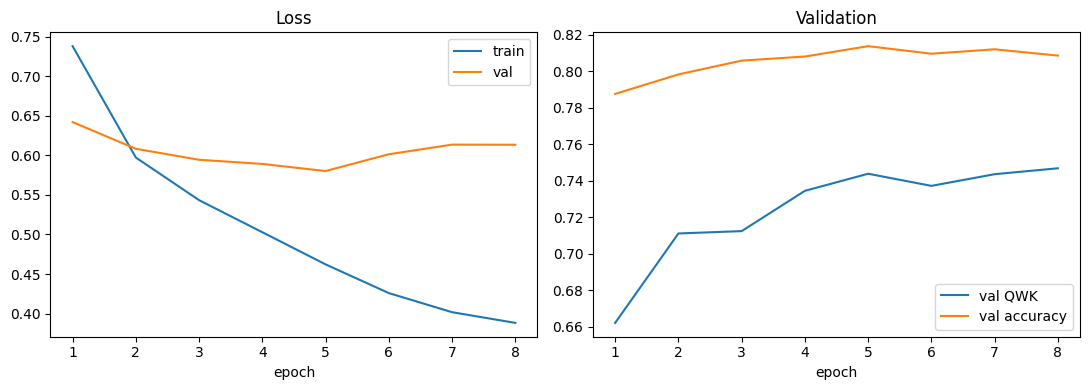

In [18]:
best = hist.loc[hist["val_qwk"].idxmax()]
print(f"Epochs run: {len(hist)} | best epoch: {int(best['epoch'])} | best validation QWK: {best['val_qwk']:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["epoch"], hist["train_loss"], label="train"); ax[0].plot(hist["epoch"], hist["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["epoch"], hist["val_qwk"], label="val QWK"); ax[1].plot(hist["epoch"], hist["val_accuracy"], label="val accuracy")
ax[1].set_title("Validation"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT_RUN / "training_curves.png", dpi=120); plt.show()

#6.Test once and log QWK
loads the best epoch and tests each dataset’s test split separately, so the results aren’t dominated by EyePACS. For an APTOS-only run the EyePACS result is a bonus cross-dataset check. Each result is printed, saved as JSON, drawn as a confusion matrix, and added to the shared table baseline_results.csv (a rerun replaces its own row, so nothing is duplicated). Look at the n per grade, because grades 3 and 4 are small in APTOS.

eval:   0%|          | 0/35 [00:00<?, ?it/s]


===== TEST: aptos (trained on) =====
n = 550 | accuracy = 0.8327 | QWK = 0.8866 | macro F1 = 0.6522
Recall per grade:
  0 No DR          0.989
  1 Mild           0.643
  2 Moderate       0.840
  3 Severe         0.276
  4 Proliferative  0.455
always-predict-No-DR accuracy: 0.493


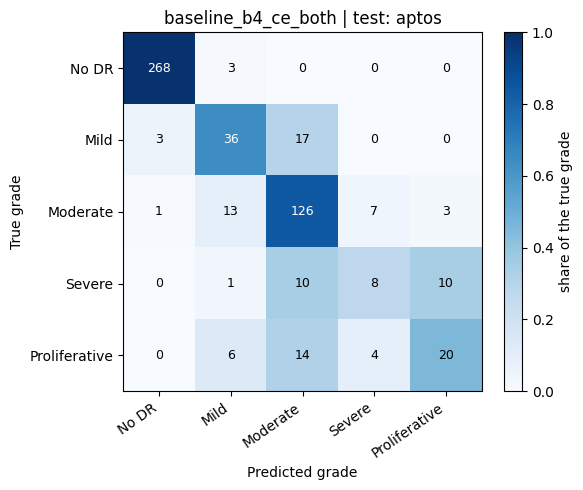

eval:   0%|          | 0/330 [00:00<?, ?it/s]


===== TEST: eyepacs (trained on) =====
n = 5270 | accuracy = 0.8165 | QWK = 0.7220 | macro F1 = 0.5575
Recall per grade:
  0 No DR          0.960
  1 Mild           0.062
  2 Moderate       0.556
  3 Severe         0.457
  4 Proliferative  0.574
always-predict-No-DR accuracy: 0.735


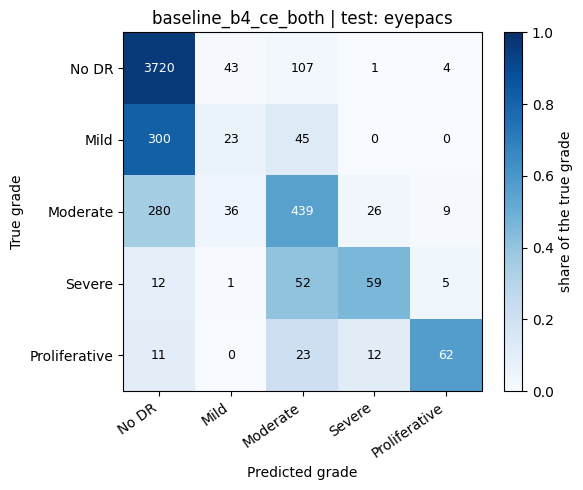

In [19]:
def log_result(ds, m, man_ds):
    cm = np.array(m["confusion_matrix"])
    recall = [cm[c, c] / cm[c].sum() if cm[c].sum() else float("nan") for c in range(5)]
    row = dict(run=RUN_NAME, trained_on=TRAIN_ON, tested_on=ds,
               in_domain=(TRAIN_ON == "both" or ds == TRAIN_ON),
               n_test=int(cm.sum()), accuracy=m["accuracy"], qwk=m["qwk"],
               always_no_dr_acc=float((man_ds[man_ds["split"] == "test"]["label"] == 0).mean()),
               best_epoch=int(best["epoch"]), best_val_qwk=float(best["val_qwk"]), epochs_run=len(hist),
               **{f"recall_{c}": recall[c] for c in range(5)},
               **{f"n_{c}": int(cm[c].sum()) for c in range(5)})
    path = OUT / "baseline_results.csv"
    new = pd.DataFrame([row])
    if path.exists():
        new = pd.concat([pd.read_csv(path), new], ignore_index=True)
        new = new.drop_duplicates(subset=["run", "tested_on"], keep="last")
    new.to_csv(path, index=False)

for ds in ["aptos", "eyepacs"]:
    man_ds = load_manifest(PROC, datasets=ds)
    ld = build_dataloaders(man_ds, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
                           num_workers=CFG["train"]["num_workers"], seed=CFG["seed"])
    m = trainer.evaluate(ld["test"], weights="best")
    tag = "trained on" if (TRAIN_ON == "both" or ds == TRAIN_ON) else "NOT in training (cross-dataset)"
    print(f"\n===== TEST: {ds} ({tag}) =====")
    print(save_metrics(m, OUT_RUN / f"test_metrics_{ds}.json"))
    print(f"always-predict-No-DR accuracy: {(man_ds[man_ds['split'] == 'test']['label'] == 0).mean():.3f}")
    plot_confusion_matrix(m["confusion_matrix"], title=f"{RUN_NAME} | test: {ds}",
                          save_path=OUT_RUN / f"confusion_matrix_{ds}.png")
    plt.show()
    log_result(ds, m, man_ds)

#Summary Table
the shared table. This is the “QWK logged” evidence for the checklist.

In [22]:
res = pd.read_csv(OUT / "baseline_results.csv")
display(res[["run", "tested_on", "in_domain", "n_test", "accuracy", "always_no_dr_acc", "qwk",
             "recall_0", "recall_1", "recall_2", "recall_3", "recall_4"]].round(3))
print("Saved in:", OUT, "(baseline_results.csv and the baseline/ folder)")
print("Checkpoints in:", RUN_DIR)

,run,tested_on,in_domain,n_test,accuracy,always_no_dr_acc,qwk,recall_0,recall_1,recall_2,recall_3,recall_4
0,baseline_b4_ce_aptos,aptos,True,550,0.804,0.493,0.859,0.982,0.482,0.767,0.448,0.477
1,baseline_b4_ce_aptos,eyepacs,False,5270,0.707,0.735,0.365,0.913,0.041,0.159,0.047,0.389
2,baseline_b4_ce_both,aptos,True,550,0.833,0.493,0.887,0.989,0.643,0.840,0.276,0.455
3,baseline_b4_ce_both,eyepacs,True,5270,0.817,0.735,0.722,0.960,0.062,0.556,0.457,0.574


Saved in: /content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/outputs (baseline_results.csv and the baseline/ folder)
Checkpoints in: /content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/checkpoints/baseline_b4_ce_both


In [21]:
import os
p = PATHS["processed"]
print(p, "| exists:", os.path.isdir(p))
names = sorted(os.listdir(p))
print(len(names), "items")
print(names[:8], "...")
print("zips:", len([n for n in names if n.endswith(".zip")]), "| manifest.csv:", "manifest.csv" in names)

/content/drive/MyDrive/FYP(Gr2-Fall 2026)/XRetina_Shared/processed | exists: True
42 items
['manifest.csv', 'meta_aptos_512_part000.csv', 'meta_aptos_512_part001.csv', 'meta_eyepacs_512_part000.csv', 'meta_eyepacs_512_part001.csv', 'meta_eyepacs_512_part002.csv', 'meta_eyepacs_512_part003.csv', 'meta_eyepacs_512_part004.csv'] ...
zips: 20 | manifest.csv: True
